# Kazakh Profanity Detection: full walkthrough

One notebook, top to bottom: **data → labels → splits → features → training → validation → test → errors → your own comment**.
Every step calls the same code as the command-line scripts in `kzprofanity/`, so the notebook and the repository give identical results.

*Works locally (from the repo, with the venv) and in a fresh Google Colab runtime (clones the repo automatically). Runtime: about 2 minutes.*

> Privacy: this notebook prints **counts and hand-written examples only**, never real review texts
> (KazSAnDRA comments can contain names). Run `results/errors.csv` locally to read the real error texts.

## 0. Setup

In [1]:
import os, sys, subprocess, json
from pathlib import Path

if 'google.colab' in sys.modules and not Path('kzprofanity').exists():
    subprocess.run(['git', 'clone', '-q', 'https://github.com/DzoTo/DL-bonus-task.git', 'repo'], check=True)
    os.chdir('repo')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], check=True)
if Path.cwd().name == 'notebooks':
    os.chdir('..')
sys.path.insert(0, str(Path.cwd()))

def run(module, *args, tail=25):
    """Run one pipeline stage exactly like `python -m kzprofanity.<module>` and show its log."""
    r = subprocess.run([sys.executable, '-m', f'kzprofanity.{module}', *args], capture_output=True, text=True,
                       encoding='utf-8', env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
    out = r.stdout.replace(str(Path.cwd()) + os.sep, '').replace(str(Path.cwd()), '.')
    print('\n'.join(out.strip().splitlines()[-tail:]))
    if r.returncode:
        print(r.stderr[-3000:]); raise RuntimeError(f'{module} failed')

import numpy as np, pandas as pd, matplotlib.pyplot as plt, yaml
from IPython.display import Markdown, Image, display
pd.set_option('display.max_colwidth', 80)
cfg = yaml.safe_load(open('config.yaml', encoding='utf-8'))
print('seed =', cfg['seed'], '| split =', cfg['split'])

seed = 42 | split = {'train': 0.7, 'val': 0.15, 'test': 0.15}


## 1. Task
Input: one Kazakh comment. Output: **1 = contains profanity (мат), 0 = clean**, plus the probability.

Labeling rules (README §3): Kazakh мат → 1 · Russian мат inside a Kazakh comment → 1 · masked / Latin / misspelled forms → 1 ·
negative-but-clean reviews → 0 · insults that are not мат (ақымақ, дебил) → 0 · innocent look-alikes (көтеру, адам, аман) → 0 ·
borderline and ambiguous words → decided by hand.

## 2. Data: KazSAnDRA, relabeled for profanity
KazSAnDRA (ISSAI, CC BY 4.0): 175k real Kazakh reviews of apps, market products, map places and books, labeled for **sentiment**.
Sentiment ≠ profanity, so the star labels are ignored and every row gets a new label.

`prepare_data`: download → scrub links/e-mails/phones/@users → drop duplicates → lexicon scan →
strong hits = auto 1 · ambiguous hits = manual review · no hit = sampled clean 0 (half of them angry 1-2★ reviews).

In [2]:
run('prepare_data')

wrote data\labeling\to_review.csv (372 rows to label)
  loaded                       175158
  pii_rows_scrubbed            406
  duplicates_removed           12010
  after_clean_dedupe           162989
  lexicon_strong_hits          2241
  lexicon_review_hits          312
  clean_pool                   160436
  insult_pool                  378
  sampled_hard_negatives       378
  sampled_angry_negatives      2500
  sampled_other_negatives      2500
  audit_rows                   60
  candidates                   7931
  review_labels_carried_over   0
  review_queue                 372


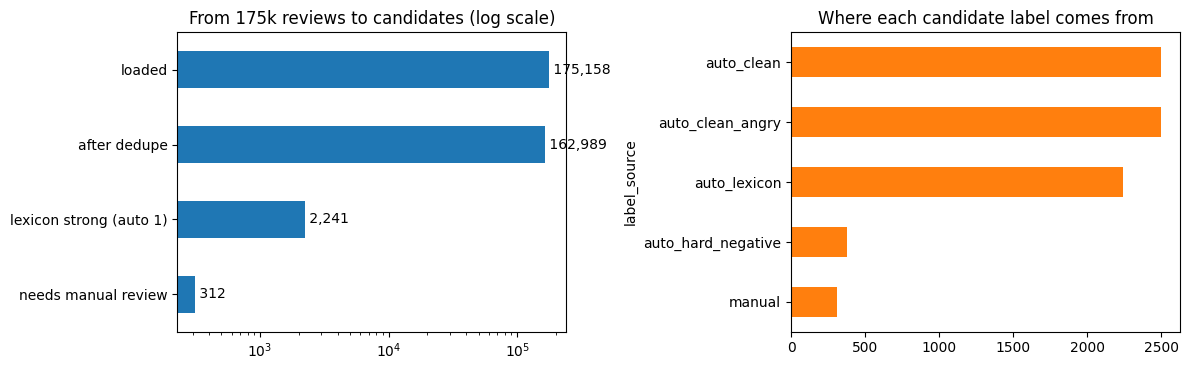

In [3]:
stats = json.load(open('data/interim/prepare_stats.json'))
cand = pd.read_csv('data/interim/candidates.csv', dtype={'id': str})
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
funnel = pd.Series({'loaded': stats['loaded'], 'after dedupe': stats['after_clean_dedupe'],
                    'lexicon strong (auto 1)': stats['lexicon_strong_hits'], 'needs manual review': stats['lexicon_review_hits']})
funnel.plot.barh(ax=ax[0], color='tab:blue', logx=True); ax[0].invert_yaxis(); ax[0].set_title('From 175k reviews to candidates (log scale)')
for i, v in enumerate(funnel): ax[0].text(v, i, f' {v:,}', va='center')
cand['label_source'].value_counts().plot.barh(ax=ax[1], color='tab:orange'); ax[1].invert_yaxis()
ax[1].set_title('Where each candidate label comes from')
plt.tight_layout(); plt.show()

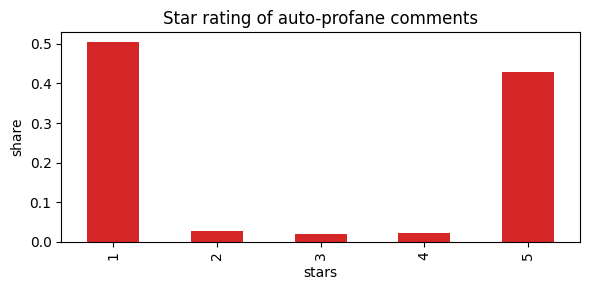

45% of profane comments have 4-5 stars -> sentiment labels cannot be reused.


In [4]:
# Is profanity just 'a bad review'? No: plenty of profane comments come with 4-5 stars ("пиздец керемет ойын").
pos = cand[cand.auto_label == 1]
share = pos['stars'].value_counts(normalize=True).sort_index()
ax = share.plot.bar(color='tab:red', figsize=(6, 3), title='Star rating of auto-profane comments')
ax.set_xlabel('stars'); ax.set_ylabel('share'); plt.tight_layout(); plt.show()
print(f'{(pos.stars >= 4).mean():.0%} of profane comments have 4-5 stars -> sentiment labels cannot be reused.')

## 3. Normalisation: `canonical()`
The same word appears in many spellings. `canonical()` maps them to one form **before** both the lexicon and the model.
It is a fixed set of rules (nothing is learned), so it cannot leak information from val/test.

In [5]:
from kzprofanity.text import canonical
examples = ['Қотақ бас', 'qotaq bas', 'к0так', 'КОТАААК!!!', 'с у к а', 'б*ять', 'Шешеңнің', 'Тауар өте нашар 👎']
pd.DataFrame({'raw': examples, 'canonical()': [canonical(e) for e in examples]})

,raw,canonical()
0,Қотақ бас,котак бас
1,qotaq bas,котак бас
2,к0так,котак
3,КОТАААК!!!,котак
4,с у к а,сука
5,б*ять,б*ят
6,Шешеңнің,шешенин
7,Тауар өте нашар 👎,тауар оте нашар


## 4. The lexicon: a search tool, not the classifier
45 regex rules in groups: `kaz`/`rus` (strong → auto label 1), `ambiguous`/`borderline` (human decides), `insult` (rude but **not** profanity → hard negatives).
Every rule has positive and look-alike tests. The lexicon is **not** given to the model as a feature.

In [6]:
from kzprofanity.lexicon import find_hits, lexicon_label, self_test
tests = ['қотақбас сатушы', 'көтерме баға', 'шешең аман болсын', 'шешеңнің амы', 'сізге сіге жаздым', 'ақымақ сатушы', 'бильярд']
pd.DataFrame({'text': tests,
              'hits': [', '.join(f'{h.rule}({h.group})' for h in find_hits(t)) or '-' for t in tests],
              'lexicon label': [{1: '1 auto', None: 'manual', 0: '0'}[lexicon_label(find_hits(t))] for t in tests]})

,text,hits,lexicon label
0,қотақбас сатушы,котак(kaz),1 auto
1,көтерме баға,-,0
2,шешең аман болсын,-,0
3,шешеңнің амы,"relative_am(kaz), ам(ambiguous)",1 auto
4,сізге сіге жаздым,сиг_other(ambiguous),manual
5,ақымақ сатушы,insult(insult),0
6,бильярд,-,0


In [7]:
self_test();

lexicon self-test: 148/148 passed, 45 rules


## 5. Splits: 70 / 15 / 15, seed 42
`make_splits`: applies manual labels (they always win over auto labels) → groups near-duplicates (same set of words) →
stratified split **by group** so copies never cross splits → asserts that no text appears in two splits.

In [8]:
run('make_splits')

manual_labels              0
  manual_unlabeled_left_out  312
  near_duplicate_groups      17
  synthetic_rows_in_train    0
  train                      {'rows': 5335, 'label_0': 3765, 'label_1': 1570}
  val                        {'rows': 1143, 'label_0': 806, 'label_1': 337}
  test                       {'rows': 1141, 'label_0': 807, 'label_1': 334}
  label_source_counts        {'auto_clean': 2500, 'auto_clean_angry': 2500, 'auto_lexicon': 2241, 'auto_hard_negative': 378}


,rows,label_0,label_1
train,5335,3765,1570
val,1143,806,337
test,1141,807,334


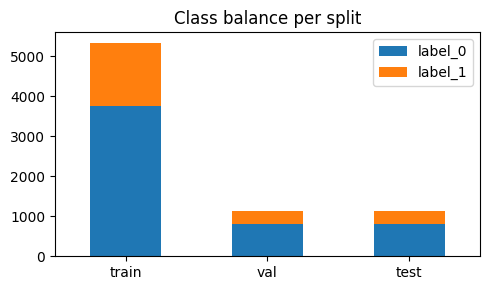

manual labels used: 0 | audit agreement: n/a (label the audit rows first)


In [9]:
st = json.load(open('data/splits/split_stats.json'))
tbl = pd.DataFrame({k: st[k] for k in ['train', 'val', 'test']}).T
display(tbl)
tbl[['label_0', 'label_1']].plot.bar(stacked=True, figsize=(5, 3), title='Class balance per split', rot=0); plt.tight_layout(); plt.show()
print('manual labels used:', st.get('manual_labels'), '| audit agreement:', st.get('audit_agreement', 'n/a (label the audit rows first)'))

## 6. From text to numbers: character n-gram TF-IDF
`TfidfVectorizer(analyzer='char_wb', ngram_range=(2,5))` cuts each word (padded with spaces) into all 2-5 letter pieces.
* Kazakh suffixes don't matter: `котак` is inside `котакбастарга`.
* Typos/masks change one piece, the rest still match.
* Unknown words: no `<UNK>` token needed. An unseen word is still made of known pieces.
* Long comments: no truncation. The whole comment becomes one vector (L2-normalised).

The vocabulary is fitted **on the training split only** (inside the sklearn `Pipeline`).

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
demo = TfidfVectorizer(preprocessor=canonical, analyzer='char_wb', ngram_range=(2, 5), lowercase=False)
demo.fit(['котакбас сатушы'])
print('n-grams of "Қотақбас сатушы":', len(demo.get_feature_names_out()))
print(list(demo.get_feature_names_out())[:40], '...')

n-grams of "Қотақбас сатушы": 52
[' к', ' ко', ' кот', ' кота', ' с', ' са', ' сат', ' сату', 'ак', 'акб', 'акба', 'акбас', 'ас', 'ас ', 'ат', 'ату', 'атуш', 'атушы', 'ба', 'бас', 'бас ', 'кб', 'кба', 'кбас', 'кбас ', 'ко', 'кот', 'кота', 'котак', 'от', 'ота', 'отак', 'отакб', 'с ', 'са', 'сат', 'сату', 'сатуш', 'та', 'так'] ...


## 7. Training: Logistic Regression, settings chosen on **validation**
Objective: L2-regularised log-loss, `class_weight='balanced'` for the 70/30 imbalance.
Grid: `C × n-gram range`. The best pair by validation F1 is kept. Then the **decision threshold** is chosen on validation (max F1).
Augmentation: masked copies (`б*ять`) of 30% of training rows *from both classes*.

In [11]:
run('train', tail=20)

train 5335 rows (29.4% profane), val 1143 rows
mask augmentation: +1601 masked copies (train only)
  C=0.1   ngrams=(1, 3)  val F1=0.9162  AP=0.9731  thr=0.476
  C=0.1   ngrams=(2, 5)  val F1=0.9333  AP=0.9806  thr=0.474
  C=0.1   ngrams=(3, 6)  val F1=0.9358  AP=0.9777  thr=0.467
  C=1.0   ngrams=(1, 3)  val F1=0.9572  AP=0.9923  thr=0.460
  C=1.0   ngrams=(2, 5)  val F1=0.9721  AP=0.9956  thr=0.398
  C=1.0   ngrams=(3, 6)  val F1=0.9686  AP=0.9940  thr=0.430
  C=10.0  ngrams=(1, 3)  val F1=0.9698  AP=0.9962  thr=0.580
  C=10.0  ngrams=(2, 5)  val F1=0.9822  AP=0.9981  thr=0.403
  C=10.0  ngrams=(3, 6)  val F1=0.9777  AP=0.9972  thr=0.371
  C=30.0  ngrams=(1, 3)  val F1=0.9708  AP=0.9964  thr=0.369
  C=30.0  ngrams=(2, 5)  val F1=0.9822  AP=0.9983  thr=0.355
  C=30.0  ngrams=(3, 6)  val F1=0.9792  AP=0.9976  thr=0.359
  C=100.0 ngrams=(1, 3)  val F1=0.9706  AP=0.9961  thr=0.407
  C=100.0 ngrams=(2, 5)  val F1=0.9851  AP=0.9984  thr=0.415
  C=100.0 ngrams=(3, 6)  val F1=0.9806  AP=0.99

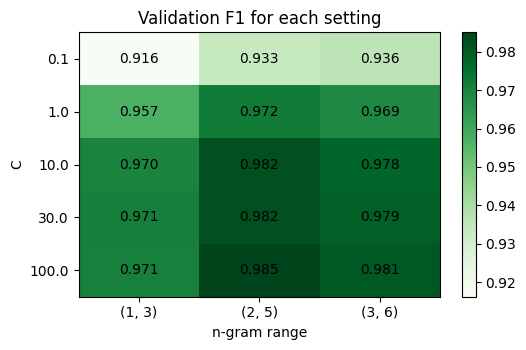

In [12]:
vs = pd.read_csv('results/val_search.csv')
grid = vs.pivot(index='C', columns='ngram_range', values='val_f1')
fig, ax = plt.subplots(figsize=(5.5, 3.6))
im = ax.imshow(grid.values, cmap='Greens', aspect='auto')
ax.set_xticks(range(grid.shape[1]), grid.columns); ax.set_yticks(range(grid.shape[0]), grid.index)
for (i, j), v in np.ndenumerate(grid.values): ax.text(j, i, f'{v:.3f}', ha='center', va='center')
ax.set_xlabel('n-gram range'); ax.set_ylabel('C'); ax.set_title('Validation F1 for each setting'); plt.colorbar(im); plt.tight_layout(); plt.show()

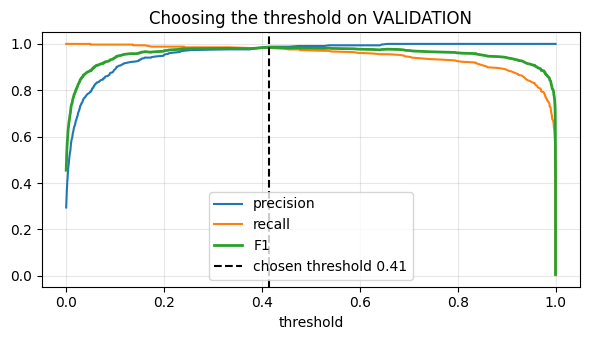

best settings: 100.0 [2, 5] | threshold 0.415


In [13]:
import joblib
from sklearn.metrics import precision_recall_curve
bundle = joblib.load('models/model.joblib'); pipe, thr = bundle['pipeline'], bundle['threshold']
val = pd.read_csv('data/processed/val.csv')
p, r, t = precision_recall_curve(val.label, pipe.predict_proba(val.text)[:, 1])
f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
plt.figure(figsize=(6, 3.5))
plt.plot(t, p[:-1], label='precision'); plt.plot(t, r[:-1], label='recall'); plt.plot(t, f1[:-1], label='F1', lw=2)
plt.axvline(thr, color='k', ls='--', label=f'chosen threshold {thr:.2f}')
plt.xlabel('threshold'); plt.title('Choosing the threshold on VALIDATION'); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
print('best settings:', bundle['classifier']['C'], bundle['features']['ngram_range'], '| threshold', round(thr, 3))

## 8. Test set: evaluated once
Nothing below changes the model. `evaluate` only reads the saved model and the test split.

In [14]:
run('evaluate')

TEST  n=1141 (profane 334)  threshold=0.415
      precision=0.9969  recall=0.9581  F1=0.9771  AP=0.9968
      confusion [[TN FP][FN TP]] = [[806 1] [14 320]]
      lexicon-only F1=1.0   errors: 15 -> results/errors.csv
CHALLENGE n=40  model F1=0.8235  lexicon F1=0.9189


| | precision | recall | F1 | TP | FP | FN | TN |
|---|---|---|---|---|---|---|---|
| **model (test)** | 0.997 | 0.958 | 0.977 | 320 | 1 | 14 | 806 |
| lexicon only (test) | 1.000 | 1.000 | 1.000 | 334 | 0 | 0 | 807 |
| always 0 (test) | 0.000 | 0.000 | 0.000 | 0 | 0 | 334 | 807 |
| model (challenge set) | 1.000 | 0.700 | 0.824 | 14 | 0 | 6 | 20 |
| lexicon only (challenge set) | 1.000 | 0.850 | 0.919 | 17 | 0 | 3 | 20 |


n_test = 1141 (334 profane) | threshold 0.4148 | ROC-AUC 0.998 | AP 0.9968


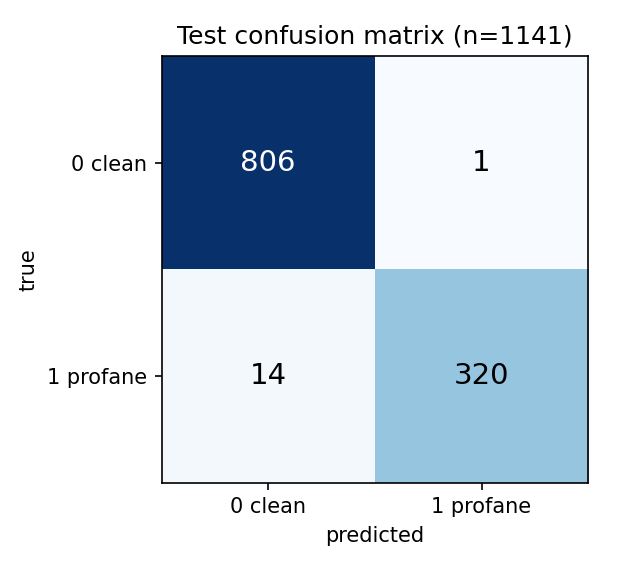

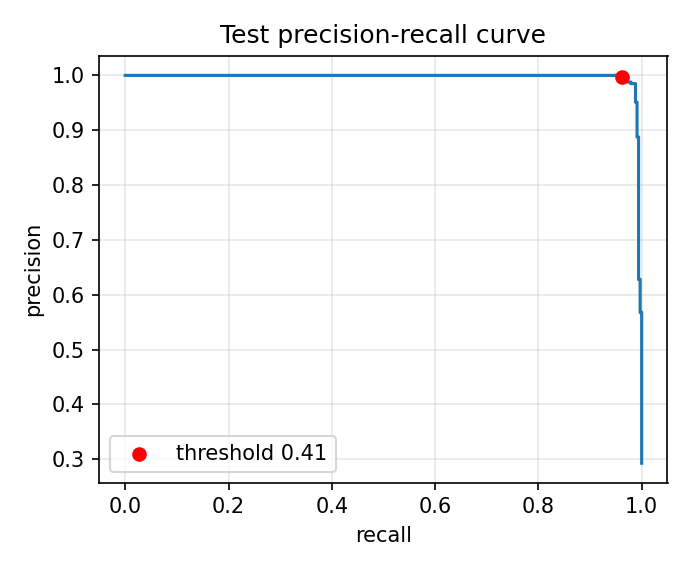

In [15]:
display(Markdown(open('results/metrics.md', encoding='utf-8').read()))
m = json.load(open('results/metrics.json'))['test']
print(f"n_test = {m['n_test']} ({m['n_test_profane']} profane) | threshold {m['threshold']} | ROC-AUC {m['roc_auc']} | AP {m['average_precision']}")
display(Image('results/confusion_matrix.png', width=380)); display(Image('results/pr_curve.png', width=420))

**Reading the table**
* precision = TP / (TP + FP): of the comments flagged, how many really were profane.
* recall = TP / (TP + FN): of the profane comments, how many were caught.
* F1 = harmonic mean of the two. Accuracy is not used: "always 0" already gets ~70% accuracy.
* **FP** = a clean (maybe angry) review gets hidden, which is unfair to the customer. **FN** = мат gets published, which hurts the platform.
* *Lexicon only = 1.0 on test is circular:* most test labels were made by the lexicon. The challenge set and the error analysis show what the model learned beyond it.

## 9. What did the model learn? Tracing one comment

canonical: сатушы далбайоп | active n-grams: 51
logit = intercept -5.726 + Σ tfidf·weight = 6.539  ->  sigmoid = 0.9986  ->  label 1


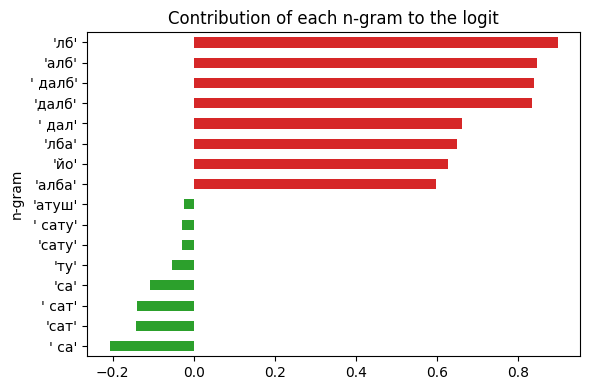

In [16]:
from kzprofanity.model import explain
e = explain(pipe, 'сатушы далбайоп')
print('canonical:', e['canonical'], '| active n-grams:', e['n_active_ngrams'])
print(f"logit = intercept {e['intercept']} + Σ tfidf·weight = {e['logit']}  ->  sigmoid = {e['probability']}  ->  label {int(e['probability'] >= thr)}")
contrib = pd.DataFrame(e['pushes_to_profane'] + e['pushes_to_clean'], columns=['n-gram', 'contribution']).sort_values('contribution')
contrib.plot.barh(x='n-gram', y='contribution', legend=False, figsize=(6, 4),
                  color=np.where(contrib.contribution > 0, 'tab:red', 'tab:green'), title='Contribution of each n-gram to the logit')
plt.tight_layout(); plt.show()

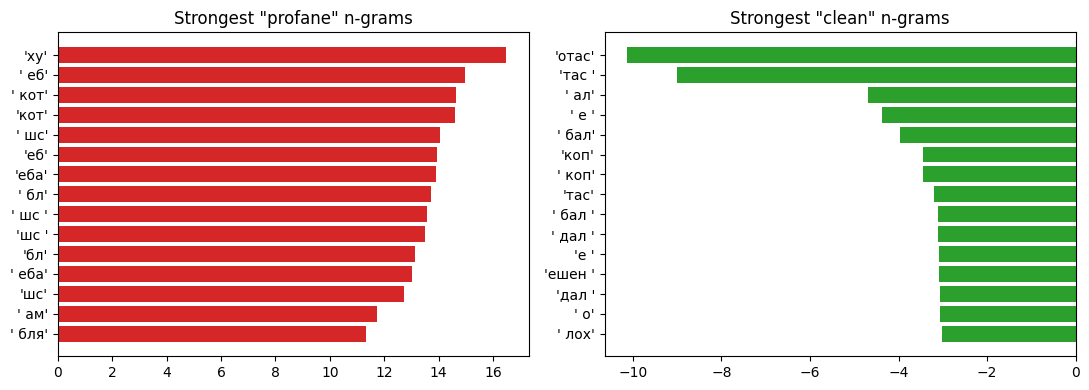

In [17]:
top = pd.read_csv('results/top_ngrams.csv').head(15)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].barh(top.profane_ngram[::-1], top.profane_weight[::-1], color='tab:red'); ax[0].set_title('Strongest "profane" n-grams')
ax[1].barh(top.clean_ngram[::-1], top.clean_weight[::-1], color='tab:green'); ax[1].set_title('Strongest "clean" n-grams')
plt.tight_layout(); plt.show()

## 10. Errors (counts only, open `results/errors.csv` locally for the texts)

In [18]:
tp = pd.read_csv('results/test_predictions.csv', dtype={'id': str})
test = pd.read_csv('data/processed/test.csv', dtype={'id': str})[['id', 'text']]
tp = tp.merge(test, on='id')
tp['words'] = tp.text.str.split().str.len()
tp['outcome'] = np.select([(tp.label == 1) & (tp.pred == 1), (tp.label == 1) & (tp.pred == 0), (tp.label == 0) & (tp.pred == 1)],
                          ['TP', 'FN', 'FP'], 'TN')
display(tp.groupby('outcome').agg(n=('id', 'size'), median_words=('words', 'median'), mean_proba=('proba', 'mean')).round(2))
med = tp.groupby('outcome').words.median()
print(f"-> missed profanity (FN) is in longer comments (median {med['FN']:.0f} words) than caught profanity (TP, {med['TP']:.0f} words):")
print('   one swear word in a long comment gets diluted by TF-IDF normalisation.')

,n,median_words,mean_proba
outcome,,,
FN,14,12.5,0.24
FP,1,4.0,0.44
TN,806,6.0,0.02
TP,320,6.0,0.96


-> missed profanity (FN) is in longer comments (median 12 words) than caught profanity (TP, 6 words):
   one swear word in a long comment gets diluted by TF-IDF normalisation.


## 11. Challenge set: 40 hand-written sentences (synthetic, never trained on)
Tests what lexicon-made test labels cannot: masks, spaced letters, new spellings, insults and innocent look-alikes.

In [19]:
ch = pd.read_csv('results/challenge.csv')
display(ch.groupby('category').apply(lambda g: pd.Series({'n': len(g), 'model correct': (g.pred == g.label).sum(),
                                                         'lexicon correct': (g.lexicon == g.label).sum()}), include_groups=False))
ch[ch.pred != ch.label][['text', 'label', 'proba', 'category']]

,n,model correct,lexicon correct
category,,,
angry_clean,2,2,2
insult_not_profanity,3,3,3
kazakh_phrase,2,2,2
kazakh_word,2,0,2
latin_translit,1,1,1
lookalike,15,15,15
masked,4,2,3
russian_in_kazakh,3,3,3
spaced_letters,1,1,1


,text,label,proba,category
3,Сатушы б**ть телефонды сындырып жіберді,1,0.0326,masked
5,Тауар х*йня екен ақша босқа,1,0.0448,masked
12,Блиаать тағы да сынық келді,1,0.3659,spelling_variant
13,Зайыбал тауар бір күнде сынды,1,0.1239,unseen_variant
18,Қаншықтар тауарды ауыстырмайды,1,0.0686,kazakh_word
19,Жәлептер ғана сатып алады мұны,1,0.1660,kazakh_word


## 12. Try your own comment (no retraining)

In [20]:
from kzprofanity.predict import predict
my_comments = ['Тауар өте нашар, ақша босқа кетті', 'Курьер ақымақ екен', 'Қ*тақ бас сатушы', 'Керемет сапа, рахмет!']
pd.DataFrame(predict(my_comments))

,text,label,probability,threshold
0,"Тауар өте нашар, ақша босқа кетті",0,0.0013,0.4148
1,Курьер ақымақ екен,0,0.0001,0.4148
2,Қ*тақ бас сатушы,1,0.9820,0.4148
3,"Керемет сапа, рахмет!",0,0.0011,0.4148


In [21]:
# Interactive version (works in Jupyter/Colab; skipped when the notebook is executed automatically)
# print(predict(input('Comment: ')))